# LAB 12 — Artificial Neural Networks: The Multi-Layer Perceptron
## Student Information
- **Name:** Haseeb Hassan
- **Roll No:** 023-24-0274
- **Section:** H
- **Date:** 26-11-2026

**Dataset:** XOR and Breast Cancer Wisconsin (sklearn built-in)

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])
print("Ready. TensorFlow", tf.__version__)


Ready. TensorFlow 2.22.0-rc1


## Part 0 — Key Concepts
Read the definitions table in the lab manual before starting.

## Part 1 — Why We Need Non-Linear Activations

### 1.1 Activation Functions and Their Slopes
**Task 1.1** — Plot the step and sigmoid functions and their derivatives (2×2 grid). Print each maximum derivative.

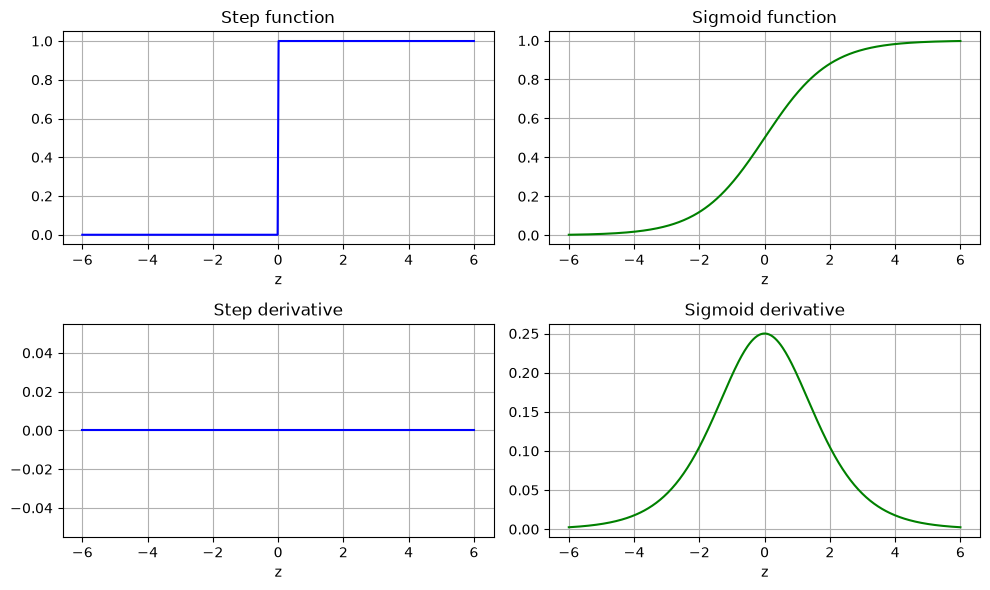

Max derivative of step    : 0.0
Max derivative of sigmoid : 0.25


In [2]:
# Task 1.1
def step(z):
    return np.where(z >= 0, 1, 0)

def step_deriv(z):
    return np.zeros_like(z, dtype=float)   # slope is 0 everywhere (except z = 0)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(z, step(z), color="blue")
axes[0, 0].set_title("Step function")
axes[0, 1].plot(z, sigmoid(z), color="green")
axes[0, 1].set_title("Sigmoid function")
axes[1, 0].plot(z, step_deriv(z), color="blue")
axes[1, 0].set_title("Step derivative")
axes[1, 1].plot(z, sigmoid_deriv(z), color="green")
axes[1, 1].set_title("Sigmoid derivative")
for ax in axes.flat:
    ax.set_xlabel("z")
    ax.grid(True)
plt.tight_layout()
plt.show()

print("Max derivative of step    :", step_deriv(z).max())
print("Max derivative of sigmoid :", round(sigmoid_deriv(z).max(), 4))

The maximum derivative of step is 0.0 and of sigmoid is 0.25 (at z = 0). The step function cannot be trained with gradient descent because its slope is zero everywhere, so the gradient is always zero and the weights never change.

### 1.2 Stacking Linear Layers Collapses
**Task 1.2** — Show that two linear layers equal one. Then add a sigmoid after the first layer and check again.

In [3]:
# Task 1.2
np.random.seed(42)
W1 = np.random.randn(2, 3)
b1 = np.random.randn(3)
W2 = np.random.randn(3, 1)
b2 = np.random.randn(1)
X = np.random.randn(5, 2)

# two linear layers
two_layer = (X @ W1 + b1) @ W2 + b2

# one layer with W = W1 @ W2 and b = b1 @ W2 + b2
W = W1 @ W2
b = b1 @ W2 + b2
one_layer = X @ W + b

print("W =", W.ravel())
print("b =", b)
print("Linear layers, allclose:", np.allclose(two_layer, one_layer))

# now put a sigmoid after the first layer
two_layer_sig = sigmoid(X @ W1 + b1) @ W2 + b2
print("With sigmoid, allclose :", np.allclose(two_layer_sig, one_layer))
print("Max difference with sigmoid:", np.abs(two_layer_sig - one_layer).max().round(4))

W = [0.03192355 1.04389051]
b = [0.9617854]
Linear layers, allclose: True
With sigmoid, allclose : False
Max difference with sigmoid: 2.0569


With only linear layers np.allclose printed True, so the two layers give the same output as one layer with W = W1 @ W2 and b = b1 @ W2 + b2. After I added a sigmoid after the first layer it printed False (the biggest difference was about 2.06). So extra layers do not add anything unless there is a non-linear activation between them.

## Part 2 — Forward Pass: An MLP Solves XOR

### 2.1 Forward Pass Function
**Task 2.1** — Write `forward`. Use the step function with W1=[[1,1],[1,1]], b1=[−0.5,−1.5], W2=[[1],[−2]], b2=[−0.5]. Print the XOR table.

In [4]:
# Task 2.1
def forward(X, W1, b1, W2, b2, f):
    h = f(X @ W1 + b1)
    y_hat = f(h @ W2 + b2)
    return h, y_hat

W1_xor = np.array([[1, 1], [1, 1]])
b1_xor = np.array([-0.5, -1.5])
W2_xor = np.array([[1], [-2]])
b2_xor = np.array([-0.5])

h, y_hat = forward(X_xor, W1_xor, b1_xor, W2_xor, b2_xor, step)

print("x1 x2 | h1 h2 | y_hat | true y")
for i in range(4):
    print(f" {X_xor[i,0]}  {X_xor[i,1]} |  {h[i,0]}  {h[i,1]} |   {y_hat[i,0]}   |   {y_xor[i]}")

print("All four correct:", np.array_equal(y_hat.ravel(), y_xor))

x1 x2 | h1 h2 | y_hat | true y
 0  0 |  0  0 |   0   |   0
 0  1 |  1  0 |   1   |   1
 1  0 |  1  0 |   1   |   1
 1  1 |  1  1 |   0   |   0
All four correct: True


The forward function matched the true y for all four rows. Hidden neuron h1 is the OR gate (it is 1 when at least one input is 1) and h2 is the AND gate (it is 1 only when both inputs are 1). The output neuron gives h1 and not h2, which is XOR.

### 2.2 The Hidden Layer Changes the Space
**Task 2.2** — Plot XOR in input space and in hidden space. Draw the line h₁ − 2h₂ − 0.5 = 0.

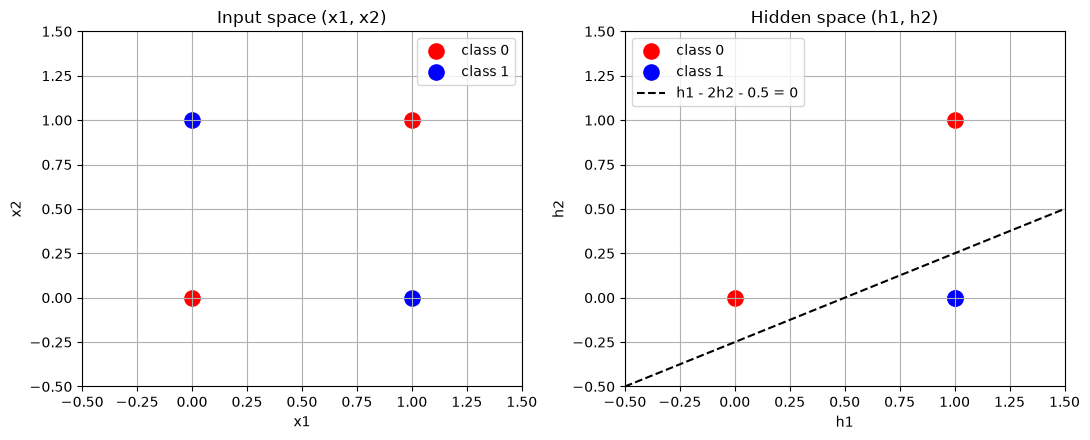

Hidden space points:
[0 0] -> [0 0] class 0
[0 1] -> [1 0] class 1
[1 0] -> [1 0] class 1
[1 1] -> [1 1] class 0


In [5]:
# Task 2.2
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# left: input space
for c, col in [(0, "red"), (1, "blue")]:
    pts = X_xor[y_xor == c]
    ax[0].scatter(pts[:, 0], pts[:, 1], c=col, s=120, label=f"class {c}")
ax[0].set_title("Input space (x1, x2)")
ax[0].set_xlabel("x1")
ax[0].set_ylabel("x2")
ax[0].set_xlim(-0.5, 1.5)
ax[0].set_ylim(-0.5, 1.5)
ax[0].legend()
ax[0].grid(True)

# right: hidden space
for c, col in [(0, "red"), (1, "blue")]:
    pts = h[y_xor == c]
    ax[1].scatter(pts[:, 0], pts[:, 1], c=col, s=120, label=f"class {c}")
h1_line = np.linspace(-0.5, 1.5, 50)
h2_line = (h1_line - 0.5) / 2          # from h1 - 2*h2 - 0.5 = 0
ax[1].plot(h1_line, h2_line, "k--", label="h1 - 2h2 - 0.5 = 0")
ax[1].set_title("Hidden space (h1, h2)")
ax[1].set_xlabel("h1")
ax[1].set_ylabel("h2")
ax[1].set_xlim(-0.5, 1.5)
ax[1].set_ylim(-0.5, 1.5)
ax[1].legend(loc="upper left")
ax[1].grid(True)

plt.tight_layout()
plt.show()

print("Hidden space points:")
for i in range(4):
    print(X_xor[i], "->", h[i], "class", y_xor[i])

In the input space the two classes sit on opposite corners, so no straight line can separate them. In the hidden space (0,1) and (1,0) both move to the point (1,0), so the class 1 points land together on one side of the line h1 - 2h2 - 0.5 = 0 and the class 0 points (0,0) and (1,1) fall on the other side.

## Part 3 — Gradient Descent and the Learning Rate

**Task 3.1** — Minimise L(w)=(w−3)² from w=−4 for 30 steps with η = 0.01, 0.1, 0.9, 1.05. Plot w vs step.

eta = 0.01  final w = -0.8184   final loss = 14.5801
eta = 0.1   final w = 2.9913   final loss = 0.0001
eta = 0.9   final w = 2.9913   final loss = 0.0001
eta = 1.05  final w = -119.1458   final loss = 14919.6003


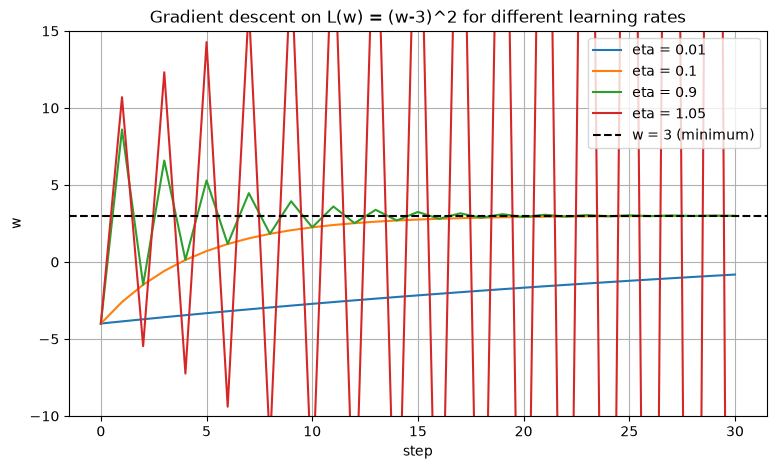

In [6]:
# Task 3.1
def loss(w):
    return (w - 3) ** 2

def gradient_descent(w0, eta, steps):
    w = w0
    ws = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)
        w = w - eta * grad
        ws.append(w)
    return ws

etas = [0.01, 0.1, 0.9, 1.05]
plt.figure(figsize=(9, 5))
for eta in etas:
    ws = gradient_descent(-4, eta, 30)
    plt.plot(ws, label=f"eta = {eta}")
    print(f"eta = {eta:<5} final w = {ws[-1]:.4f}   final loss = {loss(ws[-1]):.4f}")

plt.axhline(3, color="k", linestyle="--", label="w = 3 (minimum)")
plt.ylim(-10, 15)   # eta = 1.05 goes far outside, so the view is cut
plt.xlabel("step")
plt.ylabel("w")
plt.title("Gradient descent on L(w) = (w-3)^2 for different learning rates")
plt.legend()
plt.grid(True)
plt.show()

Eta = 0.01 is too slow: after 30 steps w is only -0.8184 and the loss is still 14.58. Eta = 0.1 is the good one: it goes smoothly to the minimum with final w = 2.9913 and loss = 0.0001. Eta = 0.9 zig-zags: w jumps from one side of 3 to the other, but the jumps get smaller and it ends at w = 2.9913. Eta = 1.05 blows up: every jump is bigger than the last and at the end w = -119.15 and the loss is 14919.6. (In the plot the y-axis is cut, so the eta = 1.05 line goes out of the picture.)

## Part 4 — Backpropagation and the Chain Rule

### 4.1 Chain Rule for One Neuron
**Task 4.1** — x=[1,2], w=[0.5,−0.3], b=0.1, y=1. Chain-rule gradient, numerical check, one update with η=0.5.

In [7]:
# Task 4.1
x = np.array([1.0, 2.0])
w = np.array([0.5, -0.3])
b = 0.1
y = 1.0

def neuron_loss(w, b):
    a = sigmoid(np.dot(w, x) + b)
    return 0.5 * (y - a) ** 2

z = np.dot(w, x) + b
a = sigmoid(z)
L = 0.5 * (y - a) ** 2
print("z =", round(z, 4), " a =", round(a, 4), " L =", round(L, 4))

# chain rule
dL_dw = -(y - a) * a * (1 - a) * x
dL_db = -(y - a) * a * (1 - a)
print("Chain rule  dL/dw =", dL_dw, " dL/db =", round(dL_db, 6))

# numerical check
eps = 0.0001
num_dw = np.zeros(2)
for i in range(2):
    w_plus = w.copy()
    w_minus = w.copy()
    w_plus[i] += eps
    w_minus[i] -= eps
    num_dw[i] = (neuron_loss(w_plus, b) - neuron_loss(w_minus, b)) / (2 * eps)
num_db = (neuron_loss(w, b + eps) - neuron_loss(w, b - eps)) / (2 * eps)
print("Numerical   dL/dw =", num_dw.round(6), " dL/db =", round(num_db, 6))
print("Match:", np.allclose(dL_dw, num_dw) and np.allclose(dL_db, num_db))

# one update
eta = 0.5
w_new = w - eta * dL_dw
b_new = b - eta * dL_db
L_new = neuron_loss(w_new, b_new)
print("New w =", w_new, " new b =", round(b_new, 4))
print("Old loss =", round(L, 4), " New loss =", round(L_new, 4))
print("Loss went down:", L_new < L)

z = 0.0  a = 0.5  L = 0.125
Chain rule  dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Numerical   dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Match: True
New w = [ 0.5625 -0.175 ]  new b = 0.1625
Old loss = 0.125  New loss = 0.083
Loss went down: True


For x = [1, 2], w = [0.5, -0.3], b = 0.1 and y = 1, I got z = 0, a = 0.5 and L = 0.125. The chain rule gave dL/dw = [-0.125, -0.25] and dL/db = -0.125, and the numerical check gave the same values, so the chain rule is correct. After one update with eta = 0.5 the new w = [0.5625, -0.175], b = 0.1625 and the loss went from 0.125 down to 0.083. Yes, the loss went down.

### 4.2 Train an MLP on XOR With Backpropagation
**Task 4.2** — 2-4-1 sigmoid MLP, η=0.5, 5000 epochs, seed 42. Plot loss and print predictions.

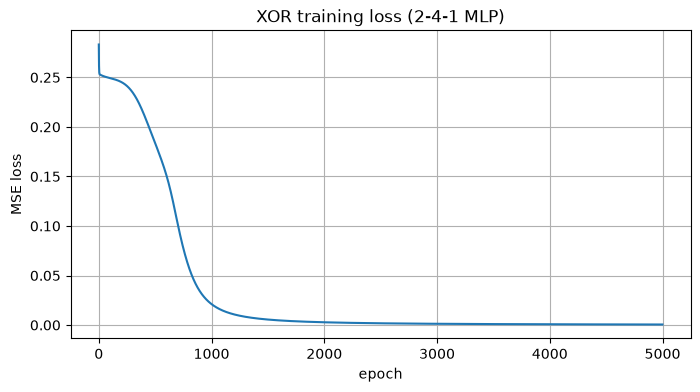

Loss at epoch 1    : 0.2832
Loss at epoch 5000 : 0.000545
Outputs A       : [0.0164 0.9785 0.9747 0.0284]
Rounded preds   : [0 1 1 0]
True y          : [0 1 1 0]
All four correct: True


In [8]:
# Task 4.2
y = y_xor.reshape(-1, 1)

np.random.seed(42)
W1 = np.random.randn(2, 4)
b1 = np.zeros(4)
W2 = np.random.randn(4, 1)
b2 = np.zeros(1)

eta = 0.5
losses = []

for epoch in range(5000):
    # forward
    H = sigmoid(X_xor @ W1 + b1)
    A = sigmoid(H @ W2 + b2)
    losses.append(np.mean((A - y) ** 2))

    # backward (all gradients first)
    dA = (A - y) * A * (1 - A)
    dW2 = H.T @ dA
    db2 = dA.sum(axis=0)
    dH = (dA @ W2.T) * H * (1 - H)
    dW1 = X_xor.T @ dH
    db1 = dH.sum(axis=0)

    # update (after all gradients are computed)
    W1 = W1 - eta * dW1
    b1 = b1 - eta * db1
    W2 = W2 - eta * dW2
    b2 = b2 - eta * db2

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.title("XOR training loss (2-4-1 MLP)")
plt.grid(True)
plt.show()

H = sigmoid(X_xor @ W1 + b1)
A = sigmoid(H @ W2 + b2)
print("Loss at epoch 1    :", round(losses[0], 4))
print("Loss at epoch 5000 :", round(losses[-1], 6))
print("Outputs A       :", A.ravel().round(4))
print("Rounded preds   :", np.round(A).ravel().astype(int))
print("True y          :", y.ravel())
print("All four correct:", np.array_equal(np.round(A).ravel(), y.ravel()))

The loss starts at 0.2832, stays close to 0.25 for the first few hundred epochs and then falls quickly, ending at 0.000545 after 5000 epochs. The final outputs are 0.0164, 0.9785, 0.9747 and 0.0284, which round to 0, 1, 1, 0 and match the true y. Yes, all four are correct, so the network found the XOR weights by itself with backpropagation.

## Part 5 — MLP in Keras on Real Data

### 5.1 Train and Evaluate an MLP
**Task 5.1** — Breast Cancer: 80/20 split (stratify), StandardScaler, 30→16→8→1 MLP with sigmoid activations, 50 epochs. Summary, test accuracy, report, loss curves.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

Trainable parameters: 641
Test accuracy: 0.9561
accuracy_score check: 0.9561
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



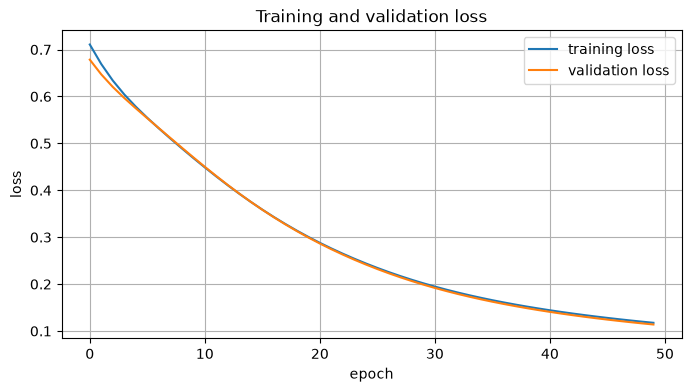

Final train loss: 0.1175  final val loss: 0.1139


In [9]:
# Task 5.1
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit on train only
X_test = scaler.transform(X_test)

tf.config.experimental.enable_op_determinism()
keras.utils.set_random_seed(42)
keras.backend.clear_session()

model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(8, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

model.summary()
trainable = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
print("Trainable parameters:", trainable)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", round(test_acc, 4))

y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print("accuracy_score check:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=data.target_names))

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)
plt.show()
print("Final train loss:", round(history.history["loss"][-1], 4),
      " final val loss:", round(history.history["val_loss"][-1], 4))

The model has 641 trainable parameters (496 + 136 + 9). Test accuracy is 0.9561 (109 of 114 correct). For malignant the precision is 0.93 and recall is 0.95, and for benign the precision is 0.97 and recall is 0.96. Training loss and validation loss go down together and end very close (0.1175 and 0.1139), so there is no sign of overfitting. The loss is still going down at epoch 50, so more epochs could help a little.

## Part 6 — Graded Questions
> Answer each question in a Markdown cell below using **your own numbers** from the lab.

**Q1 [4 marks]** — (a) Show W₂(W₁x + b₁) + b₂ = Wx + b and write W and b. (b) Why was the step function replaced by sigmoid for backpropagation?

(a) Start with W2(W1 x + b1) + b2. Open the bracket: W2 W1 x + W2 b1 + b2. Take W = W2 W1 and b = W2 b1 + b2, then it becomes Wx + b, which is just one linear layer. In my code (inputs as rows) this was W = W1 @ W2 and b = b1 @ W2 + b2, and np.allclose gave True. For my random weights W = [0.0319, 1.0439] and b = 0.9618.

(b) In my Task 1.1 plot the derivative of the step function is 0 everywhere, so backpropagation gets a zero gradient and cannot update any weight. The sigmoid derivative is a smooth curve with a maximum of 0.25 at z = 0, so there is always a gradient to send backward and the weights can be updated. That is why step was replaced by sigmoid.

**Q2 [4 marks]** — Forward pass by hand: W1=[[0.2,0.4],[0.6,−0.1]], b1=[0,0.1], W2=[[0.5],[−0.3]], b2=[0.2], x=[1,2], sigmoid everywhere. Compute h₁, h₂, ŷ (3 decimals) and check with your forward function.

In [10]:
# Q2
W1_q = np.array([[0.2, 0.4], [0.6, -0.1]])
b1_q = np.array([0, 0.1])
W2_q = np.array([[0.5], [-0.3]])
b2_q = np.array([0.2])
x_q = np.array([[1, 2]])

# step by step
z1 = x_q @ W1_q + b1_q
print("z1, z2 =", z1.ravel())
h_hand = sigmoid(z1)
print("h1, h2 =", h_hand.ravel().round(3))
z_out = h_hand @ W2_q + b2_q
print("z_out  =", z_out.ravel().round(3))
y_hand = sigmoid(z_out)
print("y_hat  =", y_hand.ravel().round(3))

# check with forward function
h_f, y_f = forward(x_q, W1_q, b1_q, W2_q, b2_q, sigmoid)
print("forward() h =", h_f.ravel().round(3), " y_hat =", y_f.ravel().round(3))
print("Same answer:", np.allclose(h_hand, h_f) and np.allclose(y_hand, y_f))

z1, z2 = [1.4 0.3]
h1, h2 = [0.802 0.574]
z_out  = [0.429]
y_hat  = [0.606]
forward() h = [0.802 0.574]  y_hat = [0.606]
Same answer: True


Hidden layer: z1 = 1(0.2) + 2(0.6) + 0 = 1.4, so h1 = sigmoid(1.4) = 0.802. z2 = 1(0.4) + 2(-0.1) + 0.1 = 0.3, so h2 = sigmoid(0.3) = 0.574.

Output: z = 0.802(0.5) + 0.574(-0.3) + 0.2 = 0.429, so y_hat = sigmoid(0.429) = 0.606.

My forward function gave h = [0.802, 0.574] and y_hat = 0.606, which is the same as my hand calculation.

**Q3 [6 marks]** — Task 4.1 neuron with y = 0: (a) ∂L/∂w₁, ∂L/∂w₂, ∂L/∂b; (b) one update with η=0.5, show the loss falls; (c) what happens with η=1.05 on a convex loss, and why?

In [11]:
# Q3
x = np.array([1.0, 2.0])
w = np.array([0.5, -0.3])
b = 0.1
y = 0.0

def neuron_loss(w, b):
    a = sigmoid(np.dot(w, x) + b)
    return 0.5 * (y - a) ** 2

# (a) gradients
z = np.dot(w, x) + b
a = sigmoid(z)
L = 0.5 * (y - a) ** 2
dL_dw = -(y - a) * a * (1 - a) * x
dL_db = -(y - a) * a * (1 - a)
print("z =", round(z, 4), " a =", round(a, 4), " L =", round(L, 4))
print("dL/dw1 =", round(dL_dw[0], 4), " dL/dw2 =", round(dL_dw[1], 4), " dL/db =", round(dL_db, 4))

# (b) one update
eta = 0.5
w_new = w - eta * dL_dw
b_new = b - eta * dL_db
L_new = neuron_loss(w_new, b_new)
print("New w =", w_new.round(4), " new b =", round(b_new, 4))
print("Loss before =", round(L, 4), " Loss after =", round(L_new, 4))
print("Loss fell:", L_new < L)

# (c) eta = 1.05 on the convex loss from Part 3
ws = gradient_descent(-4, 1.05, 30)
print("eta = 1.05, first values of w:", np.round(ws[:5], 3))
print("eta = 1.05, final w =", round(ws[-1], 2), " final loss =", round(loss(ws[-1]), 2))

z = 0.0  a = 0.5  L = 0.125
dL/dw1 = 0.125  dL/dw2 = 0.25  dL/db = 0.125
New w = [ 0.4375 -0.425 ]  new b = 0.0375
Loss before = 0.125  Loss after = 0.083
Loss fell: True
eta = 1.05, first values of w: [-4.    10.7   -5.47  12.317 -7.249]
eta = 1.05, final w = -119.15  final loss = 14919.6


(a) With y = 0: z = 0, a = 0.5 and L = 0.125. dL/dw1 = 0.125, dL/dw2 = 0.25 and dL/db = 0.125. These come from -(0 - 0.5) x 0.5 x 0.5 = 0.125, times x1 = 1, x2 = 2 and 1. They are positive because y = 0, so the neuron needs to lower its output.

(b) With eta = 0.5 the new w = [0.4375, -0.425] and b = 0.0375. The loss fell from 0.125 to 0.083, so the update worked.

(c) For L(w) = (w - 3)^2 one update gives (w - 3) -> (1 - 2 eta)(w - 3). With eta = 1.05 the factor is -1.1, so every step jumps over the minimum and lands farther away than before. In my Part 3 run w went -4, 10.7, -5.47, 12.3 and so on, and after 30 steps w = -119.15 with loss 14919.6. So even on a convex loss, a learning rate that is too large makes it diverge.

**Q4 [6 marks]** — Retrain Part 5.1 with one hidden layer of 4, 16, 64 neurons (100 epochs). Table of params, train acc, test acc; plot validation-loss curves; choose a size and comment on overfitting.

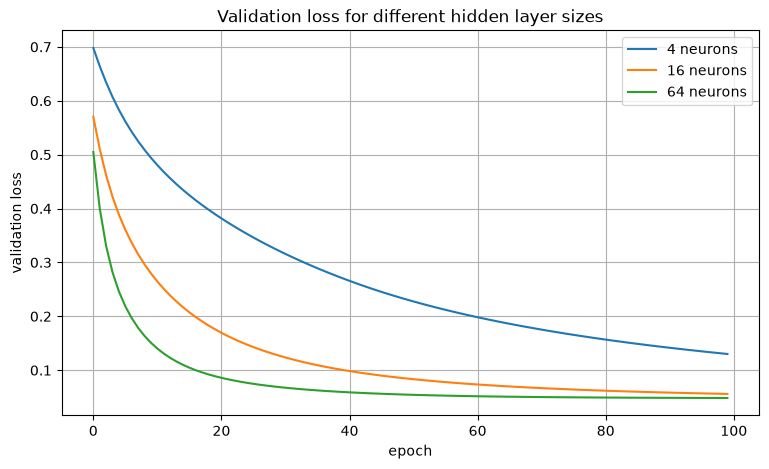

Hidden | Params | Train acc | Test acc | Final train loss | Final val loss
     4 |    129 |    0.9868 |   0.9737 |           0.1276 |         0.1301
    16 |    513 |    0.9890 |   0.9561 |           0.0601 |         0.0560
    64 |   2049 |    0.9868 |   0.9561 |           0.0492 |         0.0484


In [12]:
# Q4
sizes = [4, 16, 64]
results = []

plt.figure(figsize=(9, 5))
for n in sizes:
    keras.utils.set_random_seed(42)
    keras.backend.clear_session()
    m = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(n, activation="sigmoid"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    hist = m.fit(X_train, y_train, epochs=100, validation_split=0.2, verbose=0)

    train_acc = m.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = m.evaluate(X_test, y_test, verbose=0)[1]
    results.append((n, m.count_params(), train_acc, test_acc,
                    hist.history["loss"][-1], hist.history["val_loss"][-1]))
    plt.plot(hist.history["val_loss"], label=f"{n} neurons")

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Validation loss for different hidden layer sizes")
plt.legend()
plt.grid(True)
plt.show()

print("Hidden | Params | Train acc | Test acc | Final train loss | Final val loss")
for n, p, tr, te, tl, vl in results:
    print(f"{n:>6} | {p:>6} | {tr:>9.4f} | {te:>8.4f} | {tl:>16.4f} | {vl:>14.4f}")

The table of parameters, train accuracy and test accuracy is printed in the output above. From it: 4 hidden neurons has 129 parameters, train accuracy 0.9868 and test accuracy 0.9737. 16 hidden neurons has 513 parameters, train accuracy 0.9890 and test accuracy 0.9561. 64 hidden neurons has 2049 parameters, train accuracy 0.9868 and test accuracy 0.9561.

In the validation-loss plot the 64 neuron model drops fastest and ends lowest (0.0484), the 16 neuron model ends at 0.0560, and the 4 neuron model is the slowest and ends at 0.1301, still going down at epoch 100.

I would choose 16 neurons. Its validation loss is almost as low as 64 neurons but it uses about 4 times fewer parameters. The test accuracy of all three is very close (109 to 111 correct out of 114), so one or two patients change the order and I would not trust that small difference much. The 4 neuron model has the best test accuracy here, but it learns slowly in 100 epochs.

I do not see clear overfitting in the loss curves, because validation loss keeps going down and stays close to training loss for all three sizes. The gap between train and test accuracy is small but a bit bigger for the larger models (about 1.3% for 4, 3.3% for 16 and 3.1% for 64), so there may be a very mild sign of it.